In [18]:
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import kagglehub
from seaborn import heatmap
# Download latest version
path = kagglehub.dataset_download("payamamanat/imbd-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\ruba1\.cache\kagglehub\datasets\payamamanat\imbd-dataset\versions\1


In [2]:
import pandas as pd
import numpy as np

In [5]:
movies = pd.read_csv(f"{path}/IMBD.csv")

In [6]:
movies

,title,year,certificate,duration,genre,rating,description,stars,votes
0,Cobra Kai,(2018– ),TV-14,30 min,"Action, Comedy, Drama",8.5,Decades after their 1984 All Valley Karate Tou...,"['Ralph Macchio, ', 'William Zabka, ', 'Courtn...","177,031"
1,The Crown,(2016– ),TV-MA,58 min,"Biography, Drama, History",8.7,Follows the political rivalries and romance of...,"['Claire Foy, ', 'Olivia Colman, ', 'Imelda St...","199,885"
2,Better Call Saul,(2015–2022),TV-MA,46 min,"Crime, Drama",8.9,The trials and tribulations of criminal lawyer...,"['Bob Odenkirk, ', 'Rhea Seehorn, ', 'Jonathan...","501,384"
3,Devil in Ohio,(2022),TV-MA,356 min,"Drama, Horror, Mystery",5.9,When a psychiatrist shelters a mysterious cult...,"['Emily Deschanel, ', 'Sam Jaeger, ', 'Gerardo...","9,773"
4,Cyberpunk: Edgerunners,(2022– ),TV-MA,24 min,"Animation, Action, Adventure",8.6,A Street Kid trying to survive in a technology...,"['Zach Aguilar, ', 'Kenichiro Ohashi, ', 'Emi ...","15,413"
...,...,...,...,...,...,...,...,...,...
9952,The Imperfects,(2022– ),TV-MA,45 min,"Action, Adventure, Drama",6.3,After an experimental gene therapy turns them ...,"['Morgan Taylor Campbell, ', 'Italia Ricci, ',...","3,130"
9953,The Walking Dead,(2010–2022),TV-MA,44 min,"Drama, Horror, Thriller",8.1,Sheriff Deputy Rick Grimes wakes up from a com...,"['Andrew Lincoln, ', 'Norman Reedus, ', 'Melis...","970,067"
9954,The Crown,(2016– ),TV-MA,58 min,"Biography, Drama, History",8.7,Follows the political rivalries and romance of...,"['Claire Foy, ', 'Olivia Colman, ', 'Imelda St...","199,898"
9955,Supernatural,(2005–2020),TV-14,44 min,"Drama, Fantasy, Horror",8.4,Two brothers follow their father's footsteps a...,"['Jared Padalecki, ', 'Jensen Ackles, ', 'Jim ...","439,601"


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

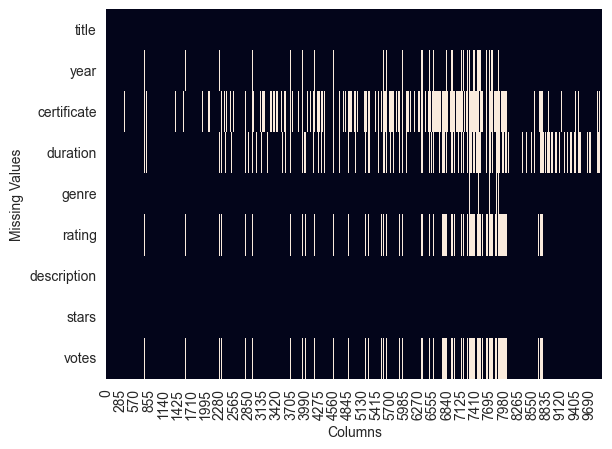

In [8]:
ax = plt.axes()
sns.heatmap(movies.isna().transpose(), cbar=False, ax=ax) #.isna - creates True/False, where True is NaN, Valse = value present | .transpose() - flips rows and columns |
#cbar = False - hides the color bar | ax=ax - draw the heatmap on the axes created.

plt.xlabel("Columns")
plt.ylabel("Missing Values")

plt.show()

In [37]:


movies["description"].value_counts()

description
Add a Plot                                                                                                                                                                                                                        289
Plot under wraps.                                                                                                                                                                                                                  25
Plot kept under wraps.                                                                                                                                                                                                             11
Plot unknown.                                                                                                                                                                                                                       9
Plot under wraps                                                    

In [13]:
movies_temp = movies.copy()

In [14]:
movies_temp = movies_temp.drop_duplicates(subset=['title'])

In [17]:
movies_temp #originally we had 9957 rows, now we have 7912

,title,year,certificate,duration,genre,rating,description,stars,votes
0,Cobra Kai,(2018– ),TV-14,30 min,"Action, Comedy, Drama",8.5,Decades after their 1984 All Valley Karate Tou...,"['Ralph Macchio, ', 'William Zabka, ', 'Courtn...","177,031"
1,The Crown,(2016– ),TV-MA,58 min,"Biography, Drama, History",8.7,Follows the political rivalries and romance of...,"['Claire Foy, ', 'Olivia Colman, ', 'Imelda St...","199,885"
2,Better Call Saul,(2015–2022),TV-MA,46 min,"Crime, Drama",8.9,The trials and tribulations of criminal lawyer...,"['Bob Odenkirk, ', 'Rhea Seehorn, ', 'Jonathan...","501,384"
3,Devil in Ohio,(2022),TV-MA,356 min,"Drama, Horror, Mystery",5.9,When a psychiatrist shelters a mysterious cult...,"['Emily Deschanel, ', 'Sam Jaeger, ', 'Gerardo...","9,773"
4,Cyberpunk: Edgerunners,(2022– ),TV-MA,24 min,"Animation, Action, Adventure",8.6,A Street Kid trying to survive in a technology...,"['Zach Aguilar, ', 'Kenichiro Ohashi, ', 'Emi ...","15,413"
...,...,...,...,...,...,...,...,...,...
8565,Alex,(2017–2019),NaN,47 min,"Action, Crime, Thriller",7.3,Add a Plot,"['Alain Darborg', '| ', ' Stars:', 'Dragomi...",33
8940,The Weekly with Wendy Mesley,(2018– ),NaN,NaN,"News, Reality-TV",NaN,How did Ontario's popular new Premier get so u...,"['Wendy Mesley, ', 'Billy Porter, ', 'Jacob To...",NaN
9520,The Drew Barrymore Show,(2020– ),TV-PG,44 min,Talk-Show,6.0,In the inaugural episode of The Drew Barrymore...,"['Adam Heydt', '| ', ' Stars:', 'Drew Barry...",19
9842,Hollywood Insider,(2018– ),NaN,NaN,Talk-Show,NaN,Behind the scenes of The Irishman.,"['Bobby Cannavale, ', 'Robert De Niro, ', 'Al ...",NaN


In [19]:
movies = movies_temp.copy() #save temp data frame to original data frame (duplicates were dropped)

In [20]:
missing_values = movies_temp.loc[(movies_temp["rating"].isna()) | (movies_temp["duration"].isna()) | (movies_temp["year"].isna()), ["title", "rating", "duration", "year"]]

In [21]:
missing_values.to_csv("missing_values.csv", index=False) #save missing ratings, duration and year with its titles in separate file

In [22]:
movies_temp.to_csv("movies_temp.csv", index=False)

In [14]:
import requests
import time

In [24]:
missing_values = pd.read_csv("missing_values.csv")

API_KEY = "5abdfb86"

def fetch_movie_info(title):
   
    url = f""
    try:
        response = requests.get(url)
        data = response.json()
        if data["Response"] == "True":
            rating = data.get("imdbRating")
            duration = data.get("Runtime")
            year = data.get("Year")
            return rating, duration, year
        else:
            return None, None, None
    except Exception as e:
        print(f"Error fetching {title}: {e}")
        return None, None, None
    
for _, row in missing_values.iterrows():  
    rating, duration, year = fetch_movie_info(row["title"])
    
    if rating not in (None, "N/A") and missing_values.loc[missing_values["title"] == row["title"], "rating"].isna().any():
        missing_values.loc[missing_values["title"] == row["title"], "rating"] = float(rating)

    if duration not in (None, "N/A") and missing_values.loc[missing_values["title"] == row["title"], "duration"].isna().any():
        missing_values.loc[missing_values["title"] == row["title"], "duration"] = int(duration.split()[0])

    if year not in (None, "N/A") and missing_values.loc[missing_values["title"] == row["title"], "year"].isna().any():
        missing_values.loc[missing_values["title"] == row["title"], "year"] = int(year.split("–")[0])

    time.sleep(0.2)  # avoid rate limits

In [26]:
missing_values.to_csv("missing_values.csv", index=False) #save requested data

In [27]:
#update data in temporary data frame
movies_temp.set_index("title", inplace=True)
missing_values.set_index("title", inplace=True)

# update only existing rows / only non-NaN values
movies_temp.update(missing_values)

# restore index
movies_temp.reset_index(inplace=True)
missing_values.reset_index(inplace=True)

In [29]:
#movies = movies_temp.copy()  # -- save temp data frame to original data frame (missing values have been filled)

In [110]:
movies.to_csv("movies.csv", index=False)

In [113]:
movies_temp = movies.copy()

In [114]:
movies_temp["words_in_description"] = movies_temp["description"].str.split().str.len()

In [49]:
remove_descriptions = [
    "add a plot",
    "plot under wraps.",
    "plot kept under wraps.",
    "plot unknown.",
    "plot under wraps",
    "plot under wraps. adaptation of the ubisoft game.",
    "the plot is under wraps."
]

In [58]:
movies = movies[~movies["description"].str.lower().isin(remove_descriptions)] #remove movies without description

In [105]:
movies = movies[~movies["description"].str.contains("plot details", case=False, na=False)] #removed descriptions with "plot is", "plot unknown", "plot kept", "plot under", "plot details"

In [119]:
movies_cleaned = movies_temp[movies_temp["words_in_description"].between(27, 300)]

In [140]:
movies_temp["tagged_description"] = movies_temp[["movie_id", "description"]].astype(str).agg(" ".join, axis=1)

In [142]:
movies_temp.to_csv("movies_cleanedFull.csv", index=False)

In [8]:
movies_temp = movies.copy()

In [14]:
movies_temp["movie_id"] = movies_temp.index + 1 #fix movies id

KeyError: 'Unnamed'

In [25]:
movies_temp[["movie_id"] + [c for c in movies_temp.columns if c != "movie_id"]].to_csv("movies.csv", index=False)

In [3]:
movies_w_e = pd.read_csv("movies_with_emotions.csv")

In [ ]:
movies_w_e["writers"] = None
movies_w_e["poster"] = None

In [ ]:
API_KEY = "5abdfb86"

def fetch_movie_info2(title):
   
    url = f""
    try:
        response = requests.get(url)
        data = response.json()
        if data["Response"] == "True":
            writer = data.get("Writers")
            poster = data.get("Poster")
            return writer, poster
        else:
            return None, None
    except Exception as e:
        print(f"Error fetching {title}: {e}")
        return None, None
    
    if "writer" not in movies_w_e.columns:
        movies_w_e["writer"] = None

    if "poster" not in movies_w_e.columns:
        movies_w_e["poster"] = None
    
for idx, row in movies_w_e[movies_w_e["writer"].isna() | movies_w_e["poster"].isna()].iterrows():
    
    writer, poster = fetch_movie_info2(row["title"])

    if writer not in (None, "N/A") and pd.isna(movies_w_e.at[idx, "writer"]):
        movies_w_e.at[idx, "writer"] = writer

    if poster not in (None, "N/A") and pd.isna(movies_w_e.at[idx, "poster"]):
        movies_w_e.at[idx, "poster"] = poster

    time.sleep(0.2) #avoid rate limits

In [23]:
movies_w_e.to_csv("movies_with_emotions.csv", index=False)